# 2.9 Filtrar y reparar registros

📍 Sensor in situ · 🪨 Tierra sólida · 📈 Sismología

🖥️ [**Diapositivas de la clase: manipular flujos de datos reales (sesión 08)**](https://geo-smart.github.io/mlgeo-book/slides/2026/lec08_repairing_records.html)

Los registros archivados llegan con efectos de filtro, huecos y errores de tiempo. En esta sección usted prueba tres reparaciones sobre un sismograma real. El registro está completo y tiene marcas de tiempo correctas, así que usted daña una copia a propósito y califica cada reparación con un número, contra el registro intacto. Las partes 2 a 4 empiezan cada una con un breve calentamiento sintético, una señal construida en unas pocas líneas cuyos tiempos verdaderos, hueco o desplazamiento fija usted, para que vea cada efecto antes de buscarlo en el registro real.

**El registro.** El 29 de julio de 2021 a las 06:15:49 UTC, el sismo Mww 8.2 de Chignik rompió la interfaz entre las placas del Pacífico y de Norteamérica al sur de la península de Alaska (evento USGS ak0219neiszm; Mww: magnitud de momento obtenida de la fase W). La estación de banda ancha UW.RATT de la Red Sísmica del Noroeste del Pacífico (Pacific Northwest Seismic Network, PNSN), en Rattlesnake Lake, en las estribaciones de las Cascadas al este de Seattle, Washington, lo registró a 2 627 km sobre el elipsoide WGS84 (World Geodetic System 1984, Sistema Geodésico Mundial de 1984), 23.56° de arco; las diapositivas dan 2 620 km, el mismo ángulo sobre una esfera a 111.2 km por grado. Usted usa su canal vertical HHZ, de 100 muestras por segundo, de 06:15 a 08:15 UTC, el mismo registro de la sección 2.8. Los valores son **cuentas crudas del digitalizador**: sin corrección instrumental. Los metadatos de la estación (StationXML) dan la sensibilidad, 5.04 × 10⁸ cuentas por m/s a 1 Hz, así que 1 000 cuentas equivalen a unos 2 µm/s de velocidad del suelo.

**Resultados de aprendizaje.** Al terminar esta sección, usted puede:
- distinguir un escalón en un registro crudo de una llegada sísmica, con un modelo de tiempos de viaje;
- elegir un filtro causal o uno de fase cero según la tarea, y medir lo que cada uno le hace a un inicio de tiempo conocido;
- filtrar por segmentos un registro con un hueco, dejar el hueco marcado como faltante y fijar un intervalo de resguardo en sus bordes;
- medir un desfase de reloj por correlación cruzada contra una referencia, a una fracción de muestra;
- decir cuál de estos problemas afecta sus propios datos, qué reparación aplicaría y qué anotaría sobre ella.

**Objetivos de hoy.** Usted va a:
- cargar la copia del curso del registro y confirmar su huella;
- localizar la llegada P y el primer escalón del registro crudo;
- medir la fase del filtro, el daño de un hueco y un desplazamiento de reloj, primero en señales sintéticas cuyas respuestas conoce;
- filtrar el registro de forma causal y con fase cero, y comparar ambos resultados en el escalón y en la onda P;
- plantar un hueco de 20 s y un error de reloj de 0.5 s en copias, reparar cada uno y calificar la reparación contra el registro intacto;
- escribir una nota breve de reparación para los datos de su proyecto.

**Cómo ejecutar este notebook.** En su clon del libro del curso, ejecute `pixi run -e core jupyter lab`: un entorno ligero, de unos 850 MB, con los paquetes que necesita este notebook. Si descargó solo este notebook, ejecute `pixi exec --spec python=3.12 --spec numpy --spec scipy --spec matplotlib --spec obspy --spec pandas --spec jupyterlab -- jupyter lab 2.9_filtering_data.ipynb` en su carpeta; el notebook descarga en `snapshots/` los datos del curso que necesita y comprueba sus huellas.

| Parte | Tema | Tiempo |
|---|---|---|
| 1 | El registro y sus propios problemas | unos 8 min |
| 2 | Fase del filtro: calentamiento sintético, luego el registro | unos 14 min |
| 3 | Huecos: calentamiento sintético, luego el registro | unos 16 min |
| 4 | Error de reloj: calentamiento sintético, luego el registro | unos 12 min |
| 5 | Los registros de su proyecto | unos 5 min |

Los tiempos son estimaciones aproximadas de cuánto toma cada parte, no un horario. Las partes suman unos 55 minutos y la clase deja unos 38 para el notebook. La celda del hueco real en la parte 3, el paso de la parábola en la parte 4 y los ejercicios son opcionales; sin ellos, las partes toman unos 50 minutos, así que prevea terminar la parte 4 o la parte 5 después de la clase.

**Celdas «Su turno».** Escriba su código entre `# --- your code` y `# --- end`. La última línea lo comprueba: imprime `correct` o una pista. Salvo que la respuesta sea correcta, la comprobación pone el resultado de referencia en lugar de cada nombre, conserva su propio valor como `<name>_yours` para comparar, y lo dice en una línea, así que las celdas siguientes corren desde la referencia. Si su celda lanza un error, comente sus líneas y vuelva a ejecutarla. Después de cada una sigue una solución desarrollada, oculta.

In [1]:
import hashlib
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import obspy
from obspy.geodetics import gps2dist_azimuth, locations2degrees
from obspy.taup import TauPyModel
from scipy import signal
import pandas as pd
import urllib.request

SNAP = Path("snapshots")          # course copies, committed with the book
OFFLINE = bool(os.environ.get("CI")) or os.environ.get("MLGEO_OFFLINE") == "1"
BOOK_URL = "https://raw.githubusercontent.com/geo-smart/mlgeo-book/main/book/Chapter2-DataManipulation/snapshots/"


DOWNLOADED = []


def course_file(name):
    # path of a course file in snapshots/; downloaded from the book repository only if it is missing
    if not (SNAP / name).exists():
        SNAP.mkdir(exist_ok=True)
        urllib.request.urlretrieve(BOOK_URL + name, SNAP / name)
        DOWNLOADED.append(name)
    return SNAP / name


read_json = lambda name: json.loads(course_file(name).read_text())
PROV = read_json("ratt_chignik_2021-07-29.provenance.json")
FILES = dict(PROV["files"])       # name -> source and fingerprint, for the five RATT files and the two map files
FILES["naturalearth_npacific_coast.csv"] = read_json("naturalearth_npacific_coast.provenance.json")
FILES["naturalearth_pnw_map.csv"] = read_json("uscrn_WA_Spokane_17_SSW_2015-2024.provenance.json")["files"]["naturalearth_pnw_map.csv"]
for name in FILES:
    course_file(name)
if DOWNLOADED:
    print(f"downloaded {len(DOWNLOADED)} missing course files from the book repository into snapshots/; fingerprints checked in Part 1")
ev, sta = PROV["event"], PROV["station"]
plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3})
print(f"{ev['title']}: {ev['origin_time_utc']}, {ev['latitude']:.2f}° N, {-ev['longitude']:.2f}° W, {ev['depth_km']} km deep")
print(f"UW.RATT, {sta['site']}: {sta['latitude']:.4f}° N, {-sta['longitude']:.4f}° W, {sta['elevation_m']} m")
print("offline mode:", OFFLINE)

M 8.2 - 2021 Chignik, Alaska Earthquake: 2021-07-29T06:15:49.188000Z, 55.36° N, 157.89° W, 35 km deep
UW.RATT, Rattlesnake Lake, King County, WA: 47.4255° N, 121.8025° W, 442.4 m
offline mode: True


In [2]:
# Checks for the Your-turn cells. You do not need to read this cell; run it once.
# your_turn(key, globals()) prints "correct", a hint that says where to look, or "not answered yet". Unless the
# answer is correct, it puts the reference result in place of each name, keeps yours as <name>_yours, and says so.
HINTS = {
    "1.step": "np.diff(raw) is largest where the surface waves are steepest, not at a step. A step is where the "
              "slope changes most abruptly: look at the second difference after 700 s (np.diff(raw, n=2) of "
              "samples i, i+1, i+2 belongs to sample i+1).",
    "1.time": "t_step should be a time in seconds after 06:15:00, between 700 and 7200, not a sample index: "
              "index the time axis t with the position you found.",
    "1.other": "look for the largest absolute second difference after 700 s, and take its time from t.",
    "2.sos": "butter takes the order, the two corners in Hz, the band type, fs=fs and output='sos'.",
    "2.zp": "the zero-phase result comes from signal.sosfiltfilt(sos, z), forward then backward.",
    "2.causal": "the causal result comes from signal.sosfilt(sos, z), forward only.",
    "2.lead": "both are times relative to t_step, so subtract t_step. lead_zp uses the window t_step - 1 to "
              "t_step + 0.5 s and the threshold on np.abs(zf); delay_c uses the 0.5 s after the step and np.abs(zc).",
    "3.seg": "start from an array of NaN of the same length, find the indices that are not NaN with np.isnan and "
             "np.flatnonzero, cut them where consecutive indices jump by more than one (np.split), and filter each "
             "piece of z_nan with signal.sosfiltfilt.",
    "3.grade": "keep the samples 0 to 2 s outside each edge (before gap[0] and from gap[1] on), take the RMS of the "
               "intact filtered record zf there as the signal, and the RMS of the difference from zf for each method; "
               "divide each error by the signal (np.sqrt, np.mean).",
    "4.shift": "a later copy has each sample at a larger index; the shift in samples is an integer; filter the "
               "copy the same way as zf.",
    "4.lag": "cc and lags must come from the same order of b and a and the same mode; lags in seconds, so divide "
             "by fs; lag_peak is the lag where cc is largest.",
    "2.syn": "both are times relative to T0_STEP, so subtract T0_STEP. lead_syn: the first sample between T0_STEP - 1 "
              "and T0_STEP + 0.5 s where abs(syn_zp) exceeds 25% of its largest value there; delay_syn: the largest "
              "abs(syn_c) in the 0.5 s after T0_STEP.",
    "3.across": "across is signal.sosfiltfilt(sos, ...) of syn_gap with its NaN set to zero by np.nan_to_num.",
    "3.apart": "apart starts as np.full(len(syn_gap), np.nan); then apart[:n0] and apart[n1:] each receive "
               "signal.sosfiltfilt(sos, ...) of the matching piece of syn_gap.",
    "4.syn": "signal.correlate(late4, ref4, mode='full') with the late train first, signal.correlation_lags with the "
             "same order and mode, divided by fs for seconds; lag4 is the lag where cc4 is largest.",
    "4.sub": "check the sign and the denominator of the correction against the formula above it; the correction "
             "is in samples, so divide by fs, and add it to lag_peak.",
}
TURNS = {"2.syn": ["lead_syn", "delay_syn"], "3.syn": ["across", "apart"], "4.syn": ["cc4", "lags4", "lag4"],
         "1.step": ["t_step"], "2.filter": ["sos", "zf", "zc"], "2.lead": ["lead_zp", "delay_c"],
         "3.segments": ["zf_seg"], "3.grade": ["ratio_naive", "ratio_seg"], "4.shift": ["z_late", "zf_late"],
         "4.lag": ["cc", "lags", "lag_peak"], "4.sub": ["lag_sub"]}
_REF = {}


def _reference(ns):
    # reference results from the notebook's record (raw, z, t, fs), computed once, with the values the tasks state:
    # 1-10 Hz band, 2 poles; gap 850-870 s; shift 0.5 s; correlation window 355-415 s
    if _REF.get("z") is ns["z"]:
        return _REF
    raw, z, t, fs = ns["raw"], ns["z"], ns["t"], ns["fs"]
    r = {"z": z}
    late = t[1:-1] > 700
    r["t_step"] = ts = float(t[1:-1][late][np.argmax(np.abs(np.diff(raw, 2))[late])])
    r["t_d1"] = float(t[1:][t[1:] > 700][np.argmax(np.abs(np.diff(raw))[t[1:] > 700])])
    r["sos"] = sos = signal.butter(2, [1, 10], "bandpass", fs=fs, output="sos")
    r["zf"], r["zc"] = zf, zc = signal.sosfiltfilt(sos, z), signal.sosfilt(sos, z)
    w, post = (t >= ts - 1) & (t < ts + 0.5), (t >= ts) & (t < ts + 0.5)
    r["lead_zp"] = float(t[w][np.argmax(np.abs(zf[w]) > 0.25 * np.abs(zf[w]).max())] - ts)
    r["delay_c"], r["peak_zp"] = (float(t[post][np.argmax(np.abs(y[post]))] - ts) for y in (zc, zf))
    i0, i1 = int(850 * fs), int(870 * fs)
    z_gap = z.copy(); z_gap[i0:i1] = 0.0
    r["zf_seg"] = np.full(len(z), np.nan)
    r["zf_seg"][:i0], r["zf_seg"][i1:] = signal.sosfiltfilt(sos, z[:i0]), signal.sosfiltfilt(sos, z[i1:])
    near = ((t >= 848) & (t < 850)) | ((t >= 870) & (t < 872))
    rms = lambda x: np.sqrt(np.mean(x[near] ** 2))
    r["ratio_naive"], r["ratio_seg"] = rms(signal.sosfiltfilt(sos, z_gap) - zf) / rms(zf), rms(r["zf_seg"] - zf) / rms(zf)
    r["z_late"] = np.roll(z, int(round(0.5 * fs)))
    r["zf_late"] = signal.sosfiltfilt(sos, r["z_late"])
    a, b = zf[int(355 * fs):int(415 * fs)], r["zf_late"][int(355 * fs):int(415 * fs)]
    r["cc"] = cc = signal.correlate(b, a, mode="full")
    r["lags"] = signal.correlation_lags(len(b), len(a), mode="full") / fs
    j = int(np.argmax(cc))
    r["lag_peak"] = float(r["lags"][j])
    r["lag_sub"] = r["lag_peak"] + 0.5 * (cc[j - 1] - cc[j + 1]) / (cc[j - 1] - 2 * cc[j] + cc[j + 1]) / fs
    _REF.clear(); _REF.update(r)
    return _REF


def _syn_reference(key, ns):
    # reference results for a synthetic warm-up, from the signals its given cells built
    fs, r = ns["fs"], {}
    sos = signal.butter(2, [1, 10], "bandpass", fs=fs, output="sos")
    if key == "2.syn":
        ts, t0, zp, c = ns["ts"], ns["T0_STEP"], ns["syn_zp"], ns["syn_c"]
        w, post = (ts >= t0 - 1) & (ts < t0 + 0.5), (ts >= t0) & (ts < t0 + 0.5)
        r["lead_syn"] = float(ts[w][np.argmax(np.abs(zp[w]) > 0.25 * np.abs(zp[w]).max())] - t0)
        r["delay_syn"], r["peak_syn_zp"] = (float(ts[post][np.argmax(np.abs(y[post]))] - t0) for y in (c, zp))
    if key == "3.syn":
        x, n0, n1 = ns["syn_gap"], ns["n0"], ns["n1"]
        r["across"] = signal.sosfiltfilt(sos, np.nan_to_num(x))
        r["apart"] = np.full(len(x), np.nan)
        r["apart"][:n0], r["apart"][n1:] = signal.sosfiltfilt(sos, x[:n0]), signal.sosfiltfilt(sos, x[n1:])
    if key == "4.syn":
        r["cc4"] = signal.correlate(ns["late4"], ns["ref4"], mode="full")
        r["lags4"] = signal.correlation_lags(len(ns["late4"]), len(ns["ref4"]), mode="full") / fs
        r["lag4"] = float(r["lags4"][np.argmax(r["cc4"])])
    return r


def _arr(v):
    try:
        return np.asarray(v, dtype=float)
    except (TypeError, ValueError):
        return None


def _close(v, ref, rtol=1e-6):
    # same shape, NaN in the same places, and close elsewhere
    a, m = _arr(v), ~np.isnan(ref)
    if a is None or a.shape != np.shape(ref) or not np.array_equal(np.isnan(a), ~m):
        return False
    return bool(np.allclose(a[m], ref[m], rtol=rtol, atol=1e-6 * np.nanmax(np.abs(ref))))


def _number(v):
    return isinstance(v, (int, float, np.integer, np.floating))


def _pair(cc, lags):
    # two one-dimensional arrays of the same length (None is tested first: _arr(None) is array(nan), not None)
    if cc is None or lags is None:
        return False
    a, b = _arr(cc), _arr(lags)
    return a is not None and b is not None and a.ndim == 1 and a.shape == b.shape


def _verdict(key, v, r):
    hint = lambda k: "not yet. Hint: " + HINTS.get(k, k)
    if key == "2.syn":
        lz, dc = v["lead_syn"], v["delay_syn"]
        if not (_number(lz) and _number(dc)):
            return hint("lead_syn and delay_syn should be two numbers in seconds. " + HINTS["2.syn"])
        if abs(lz + r["lead_syn"]) < 0.015 and abs(lz) > 0.1:
            return hint("the sign of lead_syn: subtract T0_STEP from the time you found.")
        if abs(dc - r["peak_syn_zp"]) < 0.005 and abs(dc - r["delay_syn"]) >= 0.005:
            return hint("delay_syn is the peak of the zero-phase output; use the causal output syn_c.")
        ok = abs(lz - r["lead_syn"]) < 0.015 and abs(dc - r["delay_syn"]) < 0.005
        return "correct" if ok else hint("2.syn")
    if key == "3.syn":
        if _close(v["across"], r["apart"]) and _close(v["apart"], r["across"]):
            return hint("across and apart are swapped; across is filtered straight over the zero-filled gap.")
        if not _close(v["across"], r["across"], rtol=1e-4):
            return hint("3.across")
        a = _arr(v["apart"])
        if a is not None and a.shape == r["apart"].shape and not np.array_equal(np.isnan(a), np.isnan(r["apart"])):
            return hint("the gap should stay NaN in apart: fill only the samples before n0 and from n1 on.")
        return "correct" if _close(v["apart"], r["apart"], rtol=1e-4) else hint("3.apart")
    if key == "4.syn":
        lp = v["lag4"]
        if not _pair(v["cc4"], v["lags4"]):
            return hint("cc4 and lags4 should be two arrays of the same length. " + HINTS["4.syn"])
        if np.shape(v["lags4"]) != np.shape(r["lags4"]):
            return hint("cc4 should be the full cross-correlation: mode='full' in signal.correlate and in signal.correlation_lags.")
        if not _close(v["lags4"], r["lags4"]):
            return hint("lags4 should be in seconds: signal.correlation_lags with the same order and mode, divided by fs.")
        if not _number(lp):
            return hint("lag4 should be one number in seconds. " + HINTS["4.syn"])
        if abs(lp + r["lag4"]) < 0.011:
            return hint("the sign is reversed: put the late train first in signal.correlate and in correlation_lags.")
        return "correct" if abs(lp - r["lag4"]) < 0.011 else hint("4.syn")
    if key == "1.step":
        ts = v["t_step"]
        if not _number(ts) or isinstance(ts, (int, np.integer)) or not 700 <= ts <= 7200:
            return hint("1.time")
        if abs(ts - r["t_step"]) <= 0.005:
            return "correct"
        if abs(ts - r["t_step"]) <= 0.015:
            return hint("one sample off: np.diff(raw, n=2)[i] is centred on sample i + 1, so take its time from t[1:-1].")
        return hint("1.step" if abs(ts - r["t_d1"]) <= 0.015 else "1.other")
    if key == "2.filter":
        if not _close(v["sos"], r["sos"]):
            return hint("2.sos")
        if _close(v["zf"], r["zc"]) and _close(v["zc"], r["zf"]):
            return hint("zf and zc are swapped; zf is the zero-phase result, zc the causal one.")
        if not _close(v["zf"], r["zf"]):
            return hint("2.zp")
        return "correct" if _close(v["zc"], r["zc"]) else hint("2.causal")
    if key == "2.lead":
        lz, dc = v["lead_zp"], v["delay_c"]
        if not (_number(lz) and _number(dc)):
            return hint("lead_zp and delay_c should be two numbers in seconds. " + HINTS["2.lead"])
        if abs(lz + r["lead_zp"]) < 0.015 and abs(lz) > 0.1:
            return hint("the sign of lead_zp: subtract t_step from the time you found.")
        if abs(dc - r["peak_zp"]) < 0.005 and abs(dc - r["delay_c"]) >= 0.005:
            return hint("delay_c is the peak of the zero-phase output; use the causal output zc.")
        ok = abs(lz - r["lead_zp"]) < 0.015 and abs(dc - r["delay_c"]) < 0.005
        return "correct" if ok else hint("2.lead")
    if key == "3.segments":
        a = _arr(v["zf_seg"])
        if a is None or a.shape != r["zf_seg"].shape:
            return hint("zf_seg should be one array as long as z_nan. " + HINTS["3.seg"])
        if not np.array_equal(np.isnan(a), np.isnan(r["zf_seg"])):
            return hint("the gap should stay NaN in zf_seg: fill only the indices of the valid segments.")
        return "correct" if _close(a, r["zf_seg"], rtol=1e-4) else hint("3.seg")
    if key == "3.grade":
        rn, rs = v["ratio_naive"], v["ratio_seg"]
        if not (_number(rn) and _number(rs)):
            return hint("ratio_naive and ratio_seg should be two numbers. " + HINTS["3.grade"])
        ok = abs(rn / r["ratio_naive"] - 1) < 0.02 and abs(rs / r["ratio_seg"] - 1) < 0.02
        return "correct" if ok else hint("3.grade")
    if key == "4.shift":
        ok = _close(v["z_late"], r["z_late"]) and _close(v["zf_late"], r["zf_late"])
        return "correct" if ok else hint("4.shift")
    if key == "4.lag":
        lp = v["lag_peak"]
        if not _pair(v["cc"], v["lags"]):
            return hint("cc and lags should be two arrays of the same length. " + HINTS["4.lag"])
        if np.shape(v["lags"]) != np.shape(r["lags"]):
            return hint("cc should be the full cross-correlation: mode='full' in signal.correlate and in signal.correlation_lags.")
        if not _close(v["lags"], r["lags"]):
            return hint("lags should be in seconds: signal.correlation_lags with the same order and mode, divided by fs.")
        if not _number(lp):
            return hint("lag_peak should be one number in seconds. " + HINTS["4.lag"])
        if abs(lp + r["lag_peak"]) < 0.011:
            return hint("the sign is reversed: put the late copy first in signal.correlate and in correlation_lags.")
        return "correct" if abs(lp - r["lag_peak"]) < 0.011 else hint("4.lag")
    if key == "4.sub":
        ls = v["lag_sub"]
        if not _number(ls):
            return hint("lag_sub should be one number in seconds. " + HINTS["4.sub"])
        if abs(ls - r["lag_peak"]) < 1e-9:
            return hint("that is the peak sample itself; " + HINTS["4.sub"])
        # grade the parabola correction itself: with a whole-sample shift it is tiny, so the value alone would pass
        # a flipped sign or a reversed denominator
        dc, dr = ls - r["lag_peak"], r["lag_sub"] - r["lag_peak"]
        return "correct" if abs(dc - dr) < 0.1 * abs(dr) + 1e-7 else hint("4.sub")


def your_turn(key, ns):
    r = _syn_reference(key, ns) if key.endswith(".syn") else _reference(ns)
    v = {n: ns.get(n) for n in TURNS[key]}
    verdict = "not answered yet" if all(x is None for x in v.values()) else _verdict(key, v, r)
    print(f"[{key}] {verdict}")
    if verdict == "correct":
        return
    kept = []
    for n in TURNS[key]:
        if ns.get(n) is not None:
            ns[n + "_yours"] = ns[n]
            kept.append(n + "_yours")
        ns[n] = r[n]
    note = f"; yours kept as {', '.join(kept)}" if kept else ""
    print(f"[{', '.join(TURNS[key])}] using the reference result so the next cells run{note}.")


def check_text(qid, text):
    # written answers are recorded, not graded
    words = " ".join(str(text or "").split())
    print(f"[{qid}] " + (f"recorded ({len(words.split())} words)" if words else "not answered yet"))

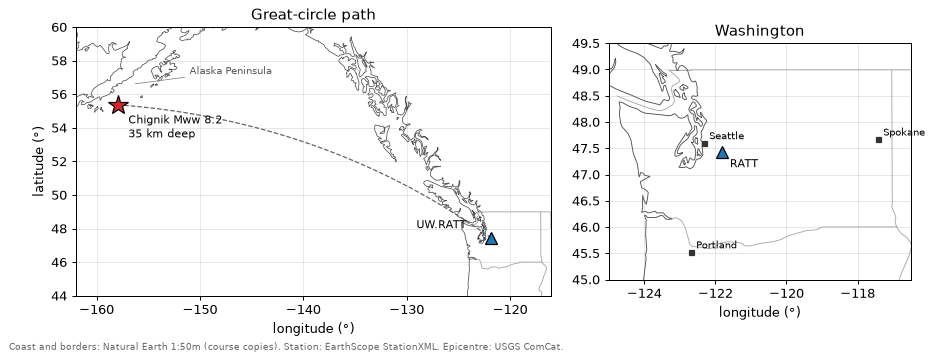

In [3]:
# great-circle path from the station to the epicentre, as points on the unit sphere
lat1, lon1, lat2, lon2 = np.radians([sta["latitude"], sta["longitude"], ev["latitude"], ev["longitude"]])
p1 = np.array([np.cos(lat1) * np.cos(lon1), np.cos(lat1) * np.sin(lon1), np.sin(lat1)])
p2 = np.array([np.cos(lat2) * np.cos(lon2), np.cos(lat2) * np.sin(lon2), np.sin(lat2)])
om = np.arccos(p1 @ p2)
frac = np.linspace(0, 1, 100)[:, None]
p = (np.sin((1 - frac) * om) * p1 + np.sin(frac * om) * p2) / np.sin(om)
gc_lat, gc_lon = np.degrees(np.arcsin(p[:, 2])), np.degrees(np.arctan2(p[:, 1], p[:, 0]))

ne = pd.read_csv(SNAP / "naturalearth_pnw_map.csv")             # Washington: coast, borders, places
coast = pd.read_csv(SNAP / "naturalearth_npacific_coast.csv")   # Alaska Peninsula to Washington, 1:50m
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10.5, 3.8), gridspec_kw={"width_ratios": [1.7, 1]})
for _, g in coast.groupby("part"):
    a1.plot(g["lon"], g["lat"], color="0.3", lw=0.6)
for _, g in ne[ne["kind"] == "border"].groupby("part"):
    a1.plot(g["lon"], g["lat"], color="0.65", lw=0.7)
a1.plot(gc_lon, gc_lat, color="0.4", ls="--", lw=1)
a1.annotate("Alaska Peninsula", (-156.5, 56.6), xytext=(-151, 57.2), fontsize=8, color="0.35",
            arrowprops=dict(arrowstyle="-", color="0.5", lw=0.6))
for (kind, part), g in ne[ne["kind"] != "place"].groupby(["kind", "part"]):
    a2.plot(g["lon"], g["lat"], color="0.3" if kind == "coastline" else "0.65", lw=0.7)
for ax in (a1, a2):
    ax.plot(sta["longitude"], sta["latitude"], "^", color="C0", ms=10, mec="k")
a1.plot(ev["longitude"], ev["latitude"], "*", color="C3", ms=16, mec="k")
a1.annotate(f"Chignik {ev['magnitude_type'].capitalize()} {ev['magnitude']}\n{ev['depth_km']} km deep",
            (ev["longitude"], ev["latitude"]), xytext=(8, -26), textcoords="offset points", fontsize=9)
a1.annotate("UW.RATT", (sta["longitude"], sta["latitude"]), xytext=(-60, 8), textcoords="offset points", fontsize=9)
a1.set(xlim=(-162, -116), ylim=(44, 60), xlabel="longitude (°)", ylabel="latitude (°)", title="Great-circle path")
a1.set_aspect(1 / np.cos(np.radians(52)))
for _, pl in ne[ne["kind"] == "place"].iterrows():
    a2.plot(pl["lon"], pl["lat"], "s", color="0.2", ms=4)
    a2.annotate(pl["name"], (pl["lon"], pl["lat"]), xytext=(4, 3), textcoords="offset points", fontsize=8)
a2.annotate("RATT", (sta["longitude"], sta["latitude"]), xytext=(6, -12), textcoords="offset points", fontsize=9)
a2.set(xlim=(-125, -116.5), ylim=(45, 49.5), xlabel="longitude (°)", title="Washington")
a2.set_aspect(1 / np.cos(np.radians(47.4)))
fig.text(0.01, 0.0, "Coast and borders: Natural Earth 1:50m (course copies). "
         "Station: EarthScope StationXML. Epicentre: USGS ComCat.", fontsize=7, color="0.4")
fig.tight_layout(rect=(0, 0.04, 1, 1))

## Parte 1. El registro y sus propios problemas (unos 8 min)

**Haga:** cargue la copia del curso, revísela, localice la onda P, encuentre el primer escalón.

La copia del curso se descargó de los servicios web FDSN de EarthScope (FDSN: International Federation of Digital Seismograph Networks, Federación Internacional de Redes Sismográficas Digitales) el 13 de octubre de 2026. Su archivo de procedencia registra la URL de origen de cada archivo y su **huella** (SHA-256, Secure Hash Algorithm), un código de 64 caracteres calculado a partir de cada byte. La celda siguiente recalcula las huellas y luego lee la forma de onda. Usted nunca escribe en el archivo: todos los daños que siguen se hacen sobre una copia en memoria.

In [4]:
for name, rec in FILES.items():                 # the five RATT files and the two map files
    sha = hashlib.sha256((SNAP / name).read_bytes()).hexdigest()
    print("matches" if sha == rec["sha256"] else "DIFFERS", sha[:16] + "...", name)

st = obspy.read(str(SNAP / "ratt_chignik_2021-07-29_UW.RATT.HHZ_0615-0815.mseed"))
raw = st[0].data.astype(float)                 # raw counts, as archived
tr = st[0].copy()
tr.detrend("linear"); tr.taper(max_percentage=0.05)
z = tr.data.astype(float)                      # trend removed, 5% taper at each end: the record we filter
fs = tr.stats.sampling_rate
t = np.arange(len(z)) / fs                     # seconds after 06:15:00 UTC
print(tr.id, tr.stats.starttime, f"{len(z):,} samples at {fs:.0f} Hz")

matches 725e3b798e3a260c... ratt_chignik_2021-07-29_UW.RATT.HHZ_0415-0615.mseed
matches 3714a18f90478fbb... ratt_chignik_2021-07-29_UW.RATT.HHZ_0615-0815.mseed
matches ed6c4e695fd23694... ratt_chignik_2021-07-29_UW.RATT.3C_062630-062830.mseed
matches f3b9111403e4924e... ratt_chignik_2021-07-29_UW.RATT.stationxml.xml
matches 5712d99e125b4098... ratt_chignik_2021-07-29_usgs_ak0219neiszm.geojson
matches 78cc93cc44ecb725... naturalearth_npacific_coast.csv
matches 7ed9da2e9ac642e9... naturalearth_pnw_map.csv
UW.RATT..HHZ 2021-07-29T06:15:00.000001Z 720,001 samples at 100 Hz


¿Dónde debería estar la onda P? El modelo de Tierra iasp91 (`obspy.taup`) da el tiempo de viaje para la profundidad del USGS y la distancia epicentral.

distance 2,627 km on the ellipsoid, 23.56° (2,620 km on a sphere)
origin 49.19 s after 06:15:00; iasp91 P travel time 307.3 s, so P at 356.5 s and S at 608.9 s
largest raw value 1.99 million counts


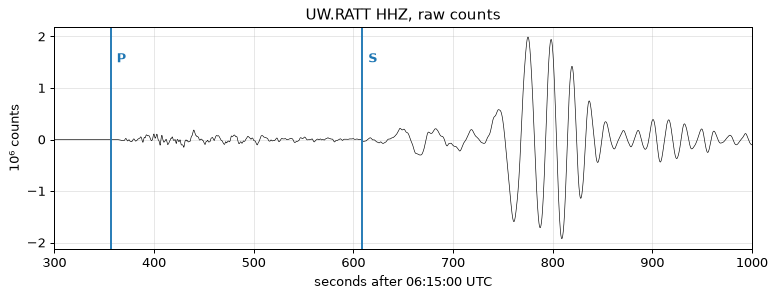

In [5]:
dist_m, _, _ = gps2dist_azimuth(ev["latitude"], ev["longitude"], sta["latitude"], sta["longitude"])
deg = locations2degrees(ev["latitude"], ev["longitude"], sta["latitude"], sta["longitude"])
origin = obspy.UTCDateTime(ev["origin_time_utc"]) - st[0].stats.starttime    # s after 06:15:00
arr = TauPyModel("iasp91").get_travel_times(ev["depth_km"], deg, ["P", "S"])
T_P = origin + min(a.time for a in arr if a.name == "P")
T_S = origin + min(a.time for a in arr if a.name == "S")
print(f"distance {dist_m / 1e3:,.0f} km on the ellipsoid, {deg:.2f}° ({deg * 111.195:,.0f} km on a sphere)")
print(f"origin {origin:.2f} s after 06:15:00; iasp91 P travel time {T_P - origin:.1f} s, so P at {T_P:.1f} s and S at {T_S:.1f} s")
print(f"largest raw value {np.abs(raw).max() / 1e6:.2f} million counts")
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.plot(t, raw / 1e6, color="k", lw=0.5)
for tt, name in [(T_P, "P"), (T_S, "S")]:
    ax.axvline(tt, color="C0", lw=1.5)
    ax.text(tt + 6, 1.5, name, color="C0", fontweight="bold")
ax.set(xlim=(300, 1000), xlabel="seconds after 06:15:00 UTC", ylabel="10⁶ counts", title="UW.RATT HHZ, raw counts");

La onda P llega unos 357 s después de las 06:15 (307.3 s de viaje; la clase usó una profundidad de 32 km, el USGS da 35 km, una diferencia de 0.4 s). Las ondas superficiales dominan después de 650 s, con oscilaciones de hasta 2 millones de cuentas.

El registro crudo tiene un problema propio. Entre 755 y 832 s, sobre las oscilaciones más empinadas de las ondas superficiales, lleva ocho **escalones**: saltos de 1 600 a 3 600 cuentas, cada uno completo en dos o tres muestras y de signo opuesto a la pendiente local. La causa no está identificada; probablemente sea el instrumento o el digitalizador. Una versión anterior de este notebook llamaba al primero de ellos el «inicio de la onda P»; llega unos 400 s después de la onda P.

**Su turno: encuentre el primer escalón.** Escriba `t_step`, el tiempo (s después de 06:15:00), posterior a 700 s, en que la pendiente del registro crudo cambia de forma más abrupta. Pruebe primero `np.diff(raw)` y mire dónde alcanza su máximo; luego mida el cambio de pendiente.

*Pista:* `np.diff(raw, n=2)` es el cambio de pendiente; `np.argmax` de su valor absoluto después de 700 s da el escalón.

In [6]:
# --- your code
t_step = None    # seconds after 06:15:00, one number
# --- end
your_turn("1.step", globals())

[1.step] not answered yet
[t_step] using the reference result so the next cells run.


*Solución desarrollada abajo (haga clic en ⋯ para abrirla).*

In [7]:
# Worked solution, open after you tried
# Names end in _sol so that running this cell keeps your own results.
d2_sol = np.abs(np.diff(raw, n=2))     # d2_sol[i] is centred on sample i + 1
after_sol = t[1:-1] > 700
t_step_sol = t[1:-1][after_sol][np.argmax(d2_sol[after_sol])]
d1 = np.abs(np.diff(raw))
print(f"first difference peaks at {t[1:][t[1:] > 700][np.argmax(d1[t[1:] > 700])]:.2f} s, the steepest surface-wave swing")
print(f"second difference peaks at {t_step_sol:.2f} s, the first step")

first difference peaks at 803.77 s, the steepest surface-wave swing
second difference peaks at 755.09 s, the first step


step at 755.09 s, 399 s after the P arrival


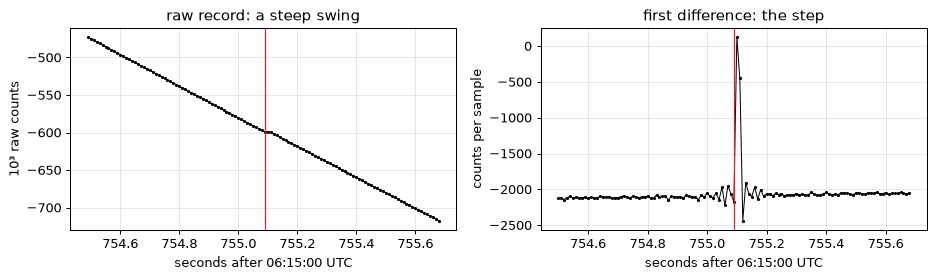

In [8]:
print(f"step at {t_step:.2f} s, {t_step - T_P:.0f} s after the P arrival")
k_step = int(round(t_step * fs))
around = slice(k_step - 60, k_step + 60)                # 0.6 s on either side of the step
fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.2))
ax[0].plot(t[around], raw[around] / 1e3, ".-", color="k", lw=0.8, ms=3)
ax[0].set(ylabel="10³ raw counts", title="raw record: a steep swing")
ax[1].plot(t[around][1:], np.diff(raw[around]), ".-", color="k", lw=0.8, ms=3)
ax[1].set(ylabel="counts per sample", title="first difference: the step")
for axi in ax:
    axi.axvline(t_step, color="C3", lw=1)
    axi.set_xlabel("seconds after 06:15:00 UTC")
fig.tight_layout()

Mire la primera diferencia justo antes del salto: desde unos 754.95 s oscila en unas ±100 cuentas por muestra. Parece el repique (*ringing*) del propio filtro antisolapamiento (*anti-alias*) de fase lineal del digitalizador antes de un cambio abrupto, como en la diapositiva de Ali y otros (2025) de la clase; esa causa es una lectura de la figura, no se prueba aquí.

## Parte 2. Fase del filtro (unos 14 min)

**Haga:** filtre de dos maneras una señal sintética con tiempos de inicio conocidos, luego el registro, y compare cada salida con el tiempo conocido.

Un filtro **causal** usa solo la muestra presente y las pasadas (`signal.sosfilt`, una pasada hacia adelante): su salida no puede empezar antes que la entrada, pero desplaza cada frecuencia en una cantidad distinta, más tarde por encima del centro de la banda y más temprano por debajo. Un filtro de **fase cero** corre hacia adelante y luego hacia atrás sobre el registro (`signal.sosfiltfilt`): no hay retardo, pero su respuesta es simétrica en el tiempo, así que aparece energía antes de un inicio abrupto. Ambos usan la banda de 1 a 10 Hz de las figuras de la clase 8, un filtro de Butterworth de 2 polos escrito como secciones de segundo orden (`sos`), que es numéricamente estable.

### Calentamiento: un registro sintético (unos 4 min)

La celda siguiente construye 20 s de señal a 100 muestras por segundo, como RATT: un escalón unitario en 5 s y una ondícula de Ricker de 5 Hz (un pulso simétrico) centrada en 12 s, en ruido blanco del 1 % del escalón.

In [9]:
ts = np.arange(0, 20, 1 / fs)                                    # 20 s at fs = 100 samples per second
T0_STEP, T0_PULSE = 5.0, 12.0                                    # s, the true times
arg = (np.pi * 5.0 * (ts - T0_PULSE)) ** 2                       # 5 Hz Ricker wavelet centred at T0_PULSE
syn = (ts >= T0_STEP) + (1 - 2 * arg) * np.exp(-arg) + 0.01 * np.random.default_rng(0).standard_normal(len(ts))

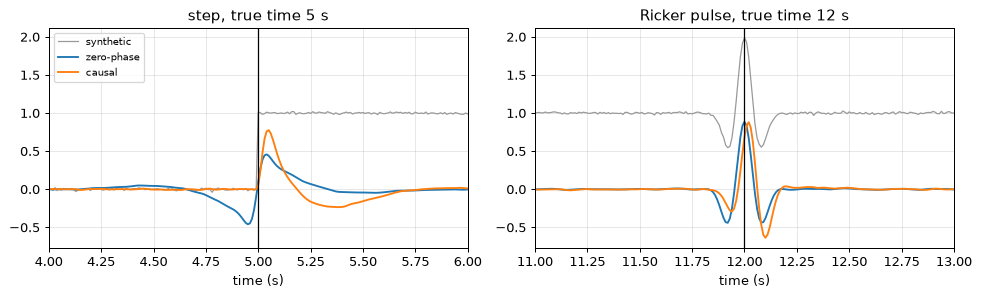

In [10]:
sos_syn = signal.butter(2, [1, 10], "bandpass", fs=fs, output="sos")   # 2-pole Butterworth, 1-10 Hz
syn_zp = signal.sosfiltfilt(sos_syn, syn)                              # zero-phase: forward, then backward
syn_c = signal.sosfilt(sos_syn, syn)                                   # causal: forward only
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
for axi, t0, name in [(ax[0], T0_STEP, "step"), (ax[1], T0_PULSE, "Ricker pulse")]:
    axi.plot(ts, syn, color="0.6", lw=1, label="synthetic")
    axi.plot(ts, syn_zp, color="C0", lw=1.5, label="zero-phase")
    axi.plot(ts, syn_c, color="C1", lw=1.5, label="causal")
    axi.axvline(t0, color="k", lw=1)
    axi.set(xlim=(t0 - 1, t0 + 1), xlabel="time (s)", title=f"{name}, true time {t0:.0f} s")
ax[0].legend(loc="upper left", fontsize=8)
fig.tight_layout()

**Su turno: mida sobre la señal sintética.** Escriba `lead_syn`, el tiempo relativo a `T0_STEP` (negativo antes de él) de la primera muestra entre `T0_STEP - 1` y `T0_STEP + 0.5` s en que `abs(syn_zp)` supera el 25 % de su valor máximo en ese intervalo; y `delay_syn`, el tiempo relativo a `T0_STEP` del mayor `abs(syn_c)` en los 0.5 s posteriores al escalón.

*Pista:* una ventana de tiempo booleana como `(ts >= T0_STEP - 1) & (ts < T0_STEP + 0.5)`, y `np.argmax` (sobre un arreglo booleano devuelve el primer True).

In [11]:
# --- your code
lead_syn = None     # seconds, your code
delay_syn = None    # seconds, your code
# --- end
your_turn("2.syn", globals())

[2.syn] not answered yet
[lead_syn, delay_syn] using the reference result so the next cells run.


*Solución desarrollada abajo (haga clic en ⋯ para abrirla).*

In [12]:
# Worked solution, open after you tried
# Names end in _sol so that running this cell keeps your own results.
w_sol = (ts >= T0_STEP - 1) & (ts < T0_STEP + 0.5)
lead_syn_sol = ts[w_sol][np.argmax(np.abs(syn_zp[w_sol]) > 0.25 * np.abs(syn_zp[w_sol]).max())] - T0_STEP
post_sol = (ts >= T0_STEP) & (ts < T0_STEP + 0.5)
delay_syn_sol = ts[post_sol][np.argmax(np.abs(syn_c[post_sol]))] - T0_STEP

In [13]:
near_pulse = (ts > T0_PULSE - 0.5) & (ts < T0_PULSE + 0.5)
print(f"step at {T0_STEP:.0f} s: zero-phase output starts {lead_syn:+.2f} s from it, causal output peaks {delay_syn:+.2f} s")
pre_s, post_s = (ts >= T0_STEP - 0.5) & (ts < T0_STEP), (ts >= T0_STEP) & (ts < T0_STEP + 0.5)
lobe_s = (ts >= T0_STEP - 1) & (ts < T0_STEP - 0.4)
print(f"zero-phase output, largest absolute value: {np.abs(syn_zp[pre_s]).max():.2f} in the 0.5 s before the step, "
      f"{np.abs(syn_zp[post_s]).max():.2f} in the 0.5 s after; {np.abs(syn_zp[lobe_s]).max():.2f} from 1 to 0.4 s before")
for name, y in [("zero-phase", syn_zp), ("causal", syn_c)]:
    print(f"pulse at {T0_PULSE:.0f} s: {name} output peaks {ts[near_pulse][np.argmax(np.abs(y[near_pulse]))] - T0_PULSE:+.2f} s from it")

step at 5 s: zero-phase output starts -0.22 s from it, causal output peaks +0.05 s
zero-phase output, largest absolute value: 0.46 in the 0.5 s before the step, 0.46 in the 0.5 s after; 0.05 from 1 to 0.4 s before
pulse at 12 s: zero-phase output peaks +0.00 s from it
pulse at 12 s: causal output peaks +0.02 s from it


La salida de fase cero empieza unos 0.2 s antes del escalón, donde la entrada es plana, y justo antes del escalón es tan grande como justo después (0.46 frente a 0.46, impresos arriba): la respuesta de fase cero a un escalón es simétrica respecto de él, con signos opuestos. Antes de eso, un lóbulo más pequeño de signo opuesto, de alrededor de una décima parte del máximo, se extiende hasta unos 0.9 s antes del escalón; un umbral más bajo, como el 10 %, lo captaría y daría un adelanto fijado por el ruido. La salida causal se mantiene plana hasta el escalón y alcanza su máximo unas pocas muestras después. Sobre el pulso simétrico, el máximo de fase cero cae exactamente en el tiempo verdadero y el máximo causal llega un par de muestras tarde.

### El registro de RATT

El mismo filtro y las mismas dos mediciones pasan ahora al registro real, donde el escalón en `t_step` ocupa el lugar del tiempo conocido. Una onda P es emergente y está enterrada en el ruido; el escalón es abrupto y su tiempo se conoce a partir de las muestras crudas, así que mide lo que hace cada filtro.

**Su turno: filtre de dos maneras.** Escriba `sos`, un pasabanda de Butterworth de 2 polos de 1 a 10 Hz como secciones de segundo orden; `zf`, `z` filtrado con fase cero; y `zc`, `z` filtrado de forma causal.

*Pista:* `signal.butter` con `output="sos"` y `fs=fs`; luego `signal.sosfiltfilt` y `signal.sosfilt`.

In [14]:
# --- your code
sos = None    # your code
zf = None     # zero-phase, your code
zc = None     # causal, your code
# --- end
your_turn("2.filter", globals())

[2.filter] not answered yet
[sos, zf, zc] using the reference result so the next cells run.


*Solución desarrollada abajo (haga clic en ⋯ para abrirla).*

In [15]:
# Worked solution, open after you tried
# Names end in _sol so that running this cell keeps your own results.
sos_sol = signal.butter(2, [1, 10], "bandpass", fs=fs, output="sos")
zf_sol = signal.sosfiltfilt(sos_sol, z)
zc_sol = signal.sosfilt(sos_sol, z)

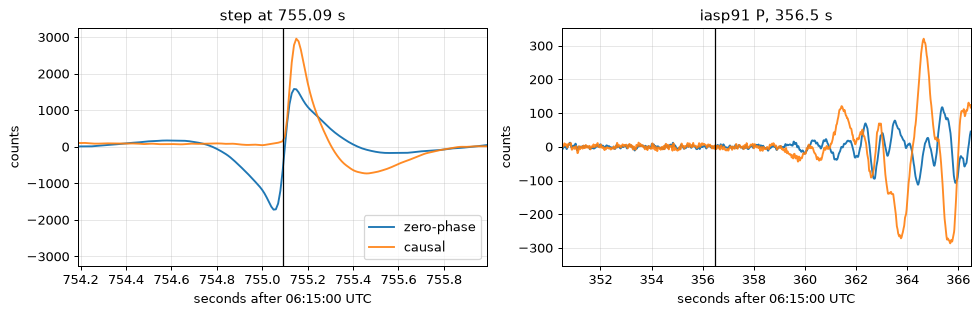

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for axi, (t0, x0, x1, title) in zip(ax, [(t_step, 0.9, 0.9, f"step at {t_step:.2f} s"), (T_P, 6, 10, f"iasp91 P, {T_P:.1f} s")]):
    axi.plot(t, zf, color="C0", lw=1.5, label="zero-phase")
    axi.plot(t, zc, color="C1", lw=1.5, alpha=0.9, label="causal")
    axi.axvline(t0, color="k", lw=1)
    near_t0 = (t > t0 - x0) & (t < t0 + x1)
    top = 1.1 * max(np.abs(zf[near_t0]).max(), np.abs(zc[near_t0]).max())
    axi.set(xlim=(t0 - x0, t0 + x1), ylim=(-top, top), xlabel="seconds after 06:15:00 UTC", ylabel="counts", title=title)
ax[0].legend(loc="lower right")
fig.tight_layout()

Mida lo que ve. La salida de fase cero debería empezar antes del escalón; la salida causal debería alcanzar su máximo después.

**Su turno: mida el adelanto y el retardo.** Escriba `lead_zp`, el tiempo relativo a `t_step` (negativo antes de él) de la primera muestra entre `t_step - 1` y `t_step + 0.5` s en que `abs(zf)` supera el 25 % de su valor máximo en ese intervalo; y `delay_c`, el tiempo relativo a `t_step` del mayor `abs(zc)` en los 0.5 s posteriores al escalón.

*Pista:* una ventana de tiempo booleana y `np.argmax` (sobre un arreglo booleano devuelve el primer True).

In [17]:
# --- your code
lead_zp = None    # seconds, your code
delay_c = None    # seconds, your code
# --- end
your_turn("2.lead", globals())

[2.lead] not answered yet
[lead_zp, delay_c] using the reference result so the next cells run.


*Solución desarrollada abajo (haga clic en ⋯ para abrirla).*

In [18]:
# Worked solution, open after you tried
# Names end in _sol so that running this cell keeps your own results.
w_sol = (t >= t_step - 1) & (t < t_step + 0.5)
lead_zp_sol = t[w_sol][np.argmax(np.abs(zf[w_sol]) > 0.25 * np.abs(zf[w_sol]).max())] - t_step
post_sol = (t >= t_step) & (t < t_step + 0.5)
delay_c_sol = t[post_sol][np.argmax(np.abs(zc[post_sol]))] - t_step

In [19]:
# time, relative to t0, of the largest absolute value of y in the `after` seconds from t0
def peak_after(t, y, t0, after=0.5):
    w = (t >= t0) & (t < t0 + after)
    return float(t[w][np.argmax(np.abs(y[w]))] - t0)


pre, bg = (t >= t_step - 0.5) & (t < t_step - 0.01), (t >= t_step - 3) & (t < t_step - 1)
post_step = (t >= t_step) & (t < t_step + 0.5)
print(f"zero-phase output starts {lead_zp:+.2f} s from the step")
print(f"peaks after the step: zero-phase {peak_after(t, zf, t_step):+.2f} s, causal {delay_c:+.2f} s")
print(f"in the 0.5 s before the step: zero-phase up to {np.abs(zf[pre]).max():,.0f} counts, causal "
      f"{np.abs(zc[pre]).max():,.0f}; in the 0.5 s after it, zero-phase up to {np.abs(zf[post_step]).max():,.0f}; "
      f"background RMS {zf[bg].std():.0f} counts")

zero-phase output starts -0.20 s from the step
peaks after the step: zero-phase +0.05 s, causal +0.06 s
in the 0.5 s before the step: zero-phase up to 1,718 counts, causal 112; in the 0.5 s after it, zero-phase up to 1,582; background RMS 45 counts


En el escalón, la salida de fase cero empieza unos 0.2 s antes y alcanza 1 718 cuentas antes del escalón, más que las 1 582 de después, frente a un fondo de 45: un detector de fases aplicado sobre ella ubicaría el inicio demasiado temprano. La figura de la clase muestra energía de fase cero unos 0.5 s antes del escalón: es el lóbulo más pequeño de signo opuesto, de alrededor de una décima parte del máximo, que el umbral del 25 % deja fuera. La salida causal se mantiene al nivel del fondo hasta el escalón y alcanza su máximo unas pocas muestras después, con la forma cambiada. Su máximo llega solo unos 0.01 s después del de fase cero, porque la subida abrupta del escalón filtrado la fija la frecuencia de esquina superior de la banda, cerca de 10 Hz, donde un filtro causal retrasa solo 0.03 s (retardo de grupo impreso abajo). El retardo es distinto en cada frecuencia, como muestra la celda siguiente.

In [20]:
BAND, POLES = (1.0, 10.0), 2      # the Part 2 filter: corners in Hz, Butterworth order passed to butter (a band-pass doubles it)


# phase delay and group delay (s) of a causal filter at the given frequencies; negative means earlier
def filter_delays(sos, fs, freqs):
    w, h = signal.sosfreqz(sos, worN=np.asarray(freqs, float), fs=fs)
    phase = -np.unwrap(np.angle(h)) / (2 * np.pi * w)
    _, gd = signal.group_delay(signal.sos2tf(sos), w=np.asarray(freqs, float), fs=fs)
    return phase, gd / fs


# first time after `start` where |y| exceeds k times the standard deviation of y over the `noise` window
def onset_above(t, y, noise=(300.0, 350.0), k=5.0, start=350.0):
    sd = float(np.std(y[(t >= noise[0]) & (t < noise[1])]))
    i = np.flatnonzero((t >= start) & (np.abs(y) > k * sd))
    return (float(t[i[0]]) if len(i) else float("nan")), sd


freqs = [0.625, 1, 3, 5, 10]
phase, group = filter_delays(sos, fs, freqs)
print(f"causal {BAND[0]:g}-{BAND[1]:g} Hz filter, order {POLES}; negative means earlier")
for f_, ph, gd in zip(freqs, phase, group):
    print(f"  {f_:5.3f} Hz: phase delay {ph:+.3f} s, group delay {gd:+.3f} s")

# lag of x behind y (s; negative means earlier), from the cross-correlation peak within max_lag
def lag_within(x, y, max_lag=0.6):
    c_ = signal.correlate(x - x.mean(), y - y.mean(), mode="full")
    l_ = signal.correlation_lags(len(x), len(y), mode="full") / fs
    keep = np.abs(l_) <= max_lag
    return float(l_[keep][np.argmax(c_[keep])])


p_win = (t >= 356) & (t < 376)                          # the P wave train
spec_f = np.fft.rfftfreq(p_win.sum(), 1 / fs)
f_peak = spec_f[np.argmax(np.abs(np.fft.rfft(zf[p_win] * np.hanning(p_win.sum()))))]
envelope = lambda y: np.abs(signal.hilbert(y))
print(f"P wave train, 356-376 s: filtered spectrum peaks at {f_peak:.1f} Hz; causal output against zero-phase: "
      f"cycles {lag_within(zc[p_win], zf[p_win]):+.2f} s, envelope {lag_within(envelope(zc)[p_win], envelope(zf)[p_win]):+.2f} s")
on_c, n_c = onset_above(t, zc)
on_z, n_z = onset_above(t, zf)
print(f"first sample above 5 times its noise (standard deviation over 300-350 s): causal {on_c:.2f} s "
      f"(noise {n_c:.1f} counts), zero-phase {on_z:.2f} s (noise {n_z:.1f} counts); iasp91 P {T_P:.2f} s")

causal 1-10 Hz filter, order 2; negative means earlier
  0.625 Hz: phase delay -0.570 s, group delay +0.274 s
  1.000 Hz: phase delay -0.250 s, group delay +0.273 s
  3.000 Hz: phase delay -0.003 s, group delay +0.052 s
  5.000 Hz: phase delay +0.015 s, group delay +0.038 s
  10.000 Hz: phase delay +0.025 s, group delay +0.029 s
P wave train, 356-376 s: filtered spectrum peaks at 1.0 Hz; causal output against zero-phase: cycles -0.21 s, envelope +0.23 s
first sample above 5 times its noise (standard deviation over 300-350 s): causal 359.47 s (noise 4.9 counts), zero-phase 359.97 s (noise 3.5 counts); iasp91 P 356.49 s


En la onda P las dos salidas difieren más que en el escalón. La mayor parte de la energía P que deja pasar esta banda está cerca de 1 Hz, en la frecuencia de esquina inferior (el espectro filtrado del tren de ondas P tiene su máximo en 1.0 Hz), muy por debajo del centro de la banda, unos 3.2 Hz (la media geométrica de las frecuencias de esquina). Ahí un pasabanda causal desplaza la señal con dos retardos distintos, impresos arriba. Un pulso corto se desplaza con el retardo de grupo (+0.27 s a 1 Hz), así que su máximo llega tarde, como el pulso de 5 Hz del calentamiento, que llegó 0.02 s tarde. Los ciclos de un tren de ondas largo cerca de 1 Hz se desplazan con el retardo de fase (−0.25 s), así que llegan antes. En el tren de ondas P de RATT, de 356 a 376 s, los ciclos causales se adelantan 0.21 s a los de fase cero y la envolvente se atrasa 0.23 s. La energía por encima de 3 Hz se retrasa unas centésimas de segundo. Aun así, la salida causal nunca empieza antes que la entrada.

La primera energía P por encima de cinco veces el ruido llega a 359.5 s en la salida causal y a 360.0 s en la salida de fase cero (impresos arriba), unos 3 s después del tiempo de iasp91. Un modelo de Tierra unidimensional puede errar por esa cantidad, y el inicio es emergente, con sus primeras oscilaciones del tamaño del ruido. Por eso el escalón, abrupto y de tiempo conocido, es la mejor prueba de un filtro. La regla de la clase: no interprete las pequeñas oscilaciones justo antes de un inicio abrupto en una salida de fase cero, porque el propio filtro pone energía ahí.

Cuál usar depende de la tarea: la detección en tiempo real y los estudios de lo que ocurre antes de un inicio (precursores, primeros movimientos) necesitan un filtro causal; alinear o apilar formas de onda fuera de línea se hace con fase cero. En cualquier caso, registre con los datos el tipo de filtro, las frecuencias de esquina, el número de polos y si es causal o de fase cero.

## Parte 3. Huecos (unos 16 min)

**Haga:** plante un hueco en una señal sintética y en el registro, filtre a través de él, repárelo y califique ambos resultados contra la señal intacta.

La telemetría se cae, los discos se llenan, las estaciones se reinician. Una fusión descuidada rellena las muestras faltantes con ceros, lo que convierte cada borde en un escalón del tamaño del valor del registro en ese punto.

### Calentamiento: un hueco sintético (unos 4 min)

La celda siguiente construye 60 s a 100 muestras por segundo: tres senoides de 1.5, 3.7 y 7.2 Hz, dentro de la banda de 1 a 10 Hz, sobre una oscilación lenta de 40 s, 50 veces mayor y por debajo de la banda, igual que la señal de 1 a 10 Hz en RATT va montada sobre ondas superficiales de amplitud mucho mayor. Luego marca de 25 a 30 s como faltante (NaN).

In [21]:
t3 = np.arange(0, 60, 1 / fs)                                    # 60 s at fs = 100 samples per second
clean = (np.sin(2 * np.pi * 1.5 * t3) + 0.6 * np.sin(2 * np.pi * 3.7 * t3 + 1) + 0.3 * np.sin(2 * np.pi * 7.2 * t3 + 2)
         + 50 * np.sin(2 * np.pi * t3 / 40))                     # three sines in the band, on a 40 s swell
n0, n1 = int(25 * fs), int(30 * fs)                              # a 5 s gap, 25 to 30 s
syn_gap = clean.copy(); syn_gap[n0:n1] = np.nan                  # the gap marked as missing

**Su turno: filtre a través del hueco y luego alrededor de él.** Con `sos` de la parte 2, escriba `across`: `syn_gap` con sus NaN puestos a cero, filtrado con fase cero de un lado a otro del hueco; y `apart`: un arreglo tan largo como `syn_gap`, con NaN dentro del hueco, en el que las muestras anteriores a `n0` y las muestras desde `n1` en adelante se filtran, cada grupo por separado, con fase cero.

*Pista:* `np.nan_to_num` pone los NaN a cero; `np.full(len(syn_gap), np.nan)` inicia `apart`; llene `apart[:n0]` y `apart[n1:]`.

In [22]:
# --- your code
across = None    # your code
apart = None     # your code
# --- end
your_turn("3.syn", globals())

[3.syn] not answered yet
[across, apart] using the reference result so the next cells run.


*Solución desarrollada abajo (haga clic en ⋯ para abrirla).*

In [23]:
# Worked solution, open after you tried
# Names end in _sol so that running this cell keeps your own results.
across_sol = signal.sosfiltfilt(sos, np.nan_to_num(syn_gap))
apart_sol = np.full(len(syn_gap), np.nan)
apart_sol[:n0] = signal.sosfiltfilt(sos, syn_gap[:n0])
apart_sol[n1:] = signal.sosfiltfilt(sos, syn_gap[n1:])

across the zero-filled gap: edge error 5.49 times the local signal (0.79 RMS) over 2 s outside each edge
each segment alone: edge error 0.20 times the local signal (0.79 RMS) over 2 s outside each edge


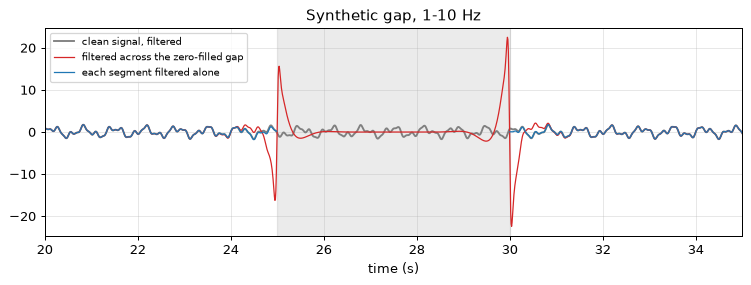

In [24]:
# RMS of (test - ref) over 0 to `width` s outside each gap edge, and the RMS of ref there (the local signal)
def edge_error(test, ref, t, gap, width=2.0):
    near = ((t >= gap[0] - width) & (t < gap[0])) | ((t >= gap[1]) & (t < gap[1] + width))
    return float(np.sqrt(np.mean((test[near] - ref[near]) ** 2))), float(np.sqrt(np.mean(ref[near] ** 2)))


clean_f = signal.sosfiltfilt(sos, clean)                         # the clean signal filtered the same way: the truth
for name, test in [("across the zero-filled gap", across), ("each segment alone", apart)]:
    err, local3 = edge_error(test, clean_f, t3, (25.0, 30.0))
    print(f"{name}: edge error {err / local3:.2f} times the local signal ({local3:.2f} RMS) over 2 s outside each edge")
fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(t3, clean_f, color="0.5", lw=1.5, label="clean signal, filtered")
ax.plot(t3, across, color="C3", lw=1, label="filtered across the zero-filled gap")
ax.plot(t3, apart, color="C0", lw=1, label="each segment filtered alone")
ax.axvspan(25, 30, color="k", alpha=0.08)
ax.set(xlim=(20, 35), xlabel="time (s)", title="Synthetic gap, 1-10 Hz")
ax.legend(loc="upper left", fontsize=8);

Los bordes rellenos con ceros son escalones de unos 35 y 49, el valor de la oscilación lenta en ese punto, y el pasabanda repica en ambos bordes con un error de varias veces la señal dentro de la banda. Filtrando por segmentos, con el hueco dejado como NaN, el error baja en más de un orden de magnitud; lo que queda cerca de cada borde es la memoria que el filtro tiene del borde, que se mide abajo como el intervalo de resguardo.

### El registro de RATT

La misma reparación, cada segmento filtrado por separado y el hueco dejado como NaN, pasa ahora al registro real, calificada con el mismo error en los bordes (lo calcula `edge_error`). Aquí usted planta un hueco de 20 s, de 850 a 870 s, dentro de las ondas superficiales, sobre una copia.

In [25]:
GAP = (850.0, 870.0)                           # s after 06:15:00 UTC, the planted gap
gap = GAP
i0, i1 = int(gap[0] * fs), int(gap[1] * fs)
z_gap = z.copy(); z_gap[i0:i1] = 0.0          # gap filled with zeros
zf_gap = signal.sosfiltfilt(sos, z_gap)       # filtered straight across the gap
z_nan = z.copy(); z_nan[i0:i1] = np.nan       # gap marked as missing
print(f"record at the edges: {z[i0 - 1]:,.0f} and {z[i1]:,.0f} counts; the 1-10 Hz signal over 2 s outside the edges "
      f"is {edge_error(zf, zf, t, gap)[1]:.0f} counts RMS")

record at the edges: 95,994 and 156,500 counts; the 1-10 Hz signal over 2 s outside the edges is 70 counts RMS


**Su turno: filtre por segmentos.** Escriba `zf_seg`: un arreglo tan largo como `z_nan`, con NaN dentro del hueco, y en el resto cada tramo de muestras válidas filtrado por separado con `sos` y fase cero. De cuatro a seis líneas.

*Pista:* `np.flatnonzero(~np.isnan(z_nan))` da los índices válidos; sepárelos con `np.split` donde `np.diff` de los índices supera 1.

In [26]:
# --- your code
zf_seg = None    # your code
# --- end
your_turn("3.segments", globals())

[3.segments] not answered yet
[zf_seg] using the reference result so the next cells run.


*Solución desarrollada abajo (haga clic en ⋯ para abrirla).*

In [27]:
# Worked solution, open after you tried
# Names end in _sol so that running this cell keeps your own results.
zf_seg_sol = np.full(len(z_nan), np.nan)
good_sol = np.flatnonzero(~np.isnan(z_nan))
for seg_sol in np.split(good_sol, np.flatnonzero(np.diff(good_sol) > 1) + 1):
    zf_seg_sol[seg_sol] = signal.sosfiltfilt(sos, z_nan[seg_sol])

Califique ambos métodos contra el registro intacto `zf`, sobre los 2 s fuera de cada borde del hueco, donde el daño es mayor.

**Su turno: califique las dos reparaciones.** Escriba `ratio_naive` y `ratio_seg`: la diferencia RMS (*root-mean-square*, raíz del valor cuadrático medio) respecto de `zf` de `zf_gap` y de `zf_seg`, sobre las muestras de 0 a 2 s fuera de cualquiera de los bordes, cada una dividida por el RMS de `zf` sobre las mismas muestras.

*Pista:* una máscara booleana `near` de esas muestras, luego `np.sqrt(np.mean(...**2))`.

In [28]:
# --- your code
ratio_naive = None    # your code
ratio_seg = None      # your code
# --- end
your_turn("3.grade", globals())

[3.grade] not answered yet
[ratio_naive, ratio_seg] using the reference result so the next cells run.


*Solución desarrollada abajo (haga clic en ⋯ para abrirla).*

In [29]:
# Worked solution, open after you tried
# Names end in _sol so that running this cell keeps your own results.
near_sol = ((t >= gap[0] - 2) & (t < gap[0])) | ((t >= gap[1]) & (t < gap[1] + 2))
sig_sol = np.sqrt(np.mean(zf[near_sol] ** 2))
ratio_naive_sol = np.sqrt(np.mean((zf_gap[near_sol] - zf[near_sol]) ** 2)) / sig_sol
ratio_seg_sol = np.sqrt(np.mean((zf_seg[near_sol] - zf[near_sol]) ** 2)) / sig_sol

edge error: filtered across the zero-filled gap 185 times the local signal; each segment alone 1.75 times
  each segment alone, 0 to 0.5 s from an edge: error 245 counts RMS
  each segment alone, 0.5 to 1 s from an edge: error 27 counts RMS
  each segment alone, 1 to 2 s from an edge: error 3 counts RMS
slope of the record within 0.5 s of the edges: up to 159,900 counts per second


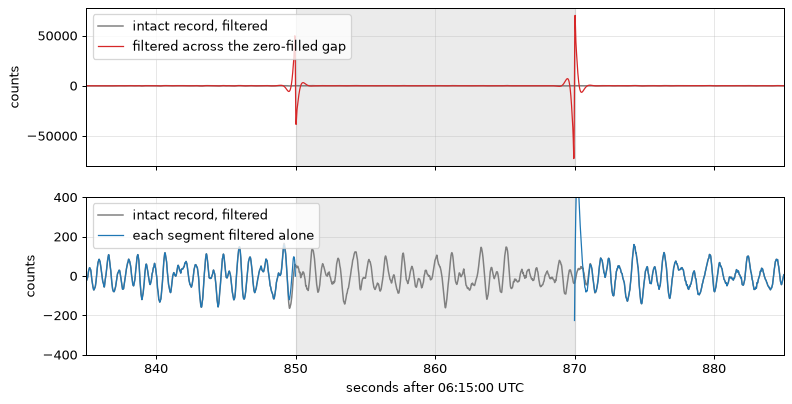

In [30]:
print(f"edge error: filtered across the zero-filled gap {ratio_naive:.0f} times the local signal; "
      f"each segment alone {ratio_seg:.2f} times")
dist_gap = np.where(t < gap[0], gap[0] - t, t - gap[1])        # s from the nearer edge, negative inside the gap
for d0, d1 in [(0, 0.5), (0.5, 1), (1, 2)]:
    m = (dist_gap >= d0) & (dist_gap < d1)
    print(f"  each segment alone, {d0:g} to {d1:g} s from an edge: error {np.sqrt(np.mean((zf_seg[m] - zf[m]) ** 2)):.0f} counts RMS")
near_edge = (dist_gap >= 0) & (dist_gap < 0.5)
print(f"slope of the record within 0.5 s of the edges: up to {np.abs(np.gradient(z, 1 / fs))[near_edge].max():,.0f} counts per second")
fig, ax = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
ax[0].plot(t, zf, color="0.5", lw=1.2, label="intact record, filtered")
ax[0].plot(t, zf_gap, color="C3", lw=1, label="filtered across the zero-filled gap")
ax[1].plot(t, zf, color="0.5", lw=1.2, label="intact record, filtered")
ax[1].plot(t, zf_seg, color="C0", lw=1, label="each segment filtered alone")
ax[1].set(ylim=(-400, 400), xlabel="seconds after 06:15:00 UTC")
for axi in ax:
    axi.axvspan(*gap, color="k", alpha=0.08)
    axi.set(xlim=(gap[0] - 15, gap[1] + 15), ylabel="counts")
    axi.legend(loc="upper left");

El hueco relleno con ceros hace repicar el filtro en ambos bordes: un escalón contiene todas las frecuencias, y el pasabanda responde en sus frecuencias de esquina. A menos de unos 2 s de cada borde, a ambos lados, la salida repica con hasta 70 000 cuentas, cientos de veces la señal local; un modelo de aprendizaje automático entrenado con ventanas cortadas a través de estos bordes aprendería del repique. Filtrar cada segmento por separado y dejar el hueco como NaN reduce el error en los bordes en dos órdenes de magnitud, y el hueco queda declarado como faltante. Por segmentos, el error sigue siendo 1.75 veces la señal local sobre esos 2 s, frente a 0.20 en el calentamiento, pero se concentra casi por completo a menos de 0.5 s de cada borde (impreso arriba), donde el registro varía hasta 160 000 cuentas por segundo: por eso existe el intervalo de resguardo.

El error que queda cerca de cada borde es la memoria que el filtro tiene del borde. ¿Hasta dónde llega? El **intervalo de resguardo** es el tramo en cada borde que se deja fuera de los análisis posteriores (la extracción de características en 2.11). La celda siguiente mide hasta qué distancia del hueco el error supera el 1 % del fondo, el RMS del registro intacto filtrado entre 5 y 60 s del hueco.

In [31]:
# seconds before and after the gap over which |test - ref| exceeds frac times the background,
# the RMS of ref 5 to 60 s from the gap; returns (before, after, background)
def guard_interval(test, ref, t, gap, frac=0.01):
    dist = np.where(t < gap[0], gap[0] - t, t - gap[1])
    out = ~np.isnan(test)
    local = np.sqrt(np.mean(ref[out & (dist > 5) & (dist < 60)] ** 2))
    bad = out & (np.abs(test - ref) > frac * local) & (dist < 200)
    before = float(dist[bad & (t < gap[0])].max()) if (bad & (t < gap[0])).any() else 0.0
    after = float(dist[bad & (t > gap[1])].max()) if (bad & (t > gap[1])).any() else 0.0
    return before, after, float(local)


before, after, bg = guard_interval(zf_seg, zf, t, gap)
guard, f_low = max(before, after), BAND[0]
print(f"background 5 to 60 s from the gap: {bg:.0f} counts RMS")
print(f"error above 1% of it for {before:.1f} s before and {after:.1f} s after the gap: a guard of about "
      f"{np.ceil(guard):.0f} s, {guard * f_low:.1f} periods of the {f_low:g} Hz lower corner")

background 5 to 60 s from the gap: 166 counts RMS
error above 1% of it for 1.1 s before and 1.6 s after the gap: a guard of about 2 s, 1.6 periods of the 1 Hz lower corner


**Opcional, solo en línea: un hueco real.** El 21 de enero de 2021 a las 17:48 UTC, UW.RATT HHZ perdió 40 s de datos en la transmisión; el archivo de datos guarda dos segmentos. La celda siguiente descarga de EarthScope unos 21 minutos alrededor del hueco y califica el relleno con ceros contra el filtrado por segmentos, como hizo la figura de la clase (un error máximo en el borde de unas 13 veces la señal local, durante aproximadamente 1 s). Su intervalo de resguardo se mide contra la señal local completa, no contra el 1 % de ella como arriba, porque el registro real no tiene una copia intacta contra la cual calificar, solo el resultado por segmentos. Se omite cuando el notebook corre sin conexión.

In [32]:
if OFFLINE:
    print("offline mode: skipped (online it downloads about 21 minutes of UW.RATT HHZ from EarthScope)")
else:
    try:
        # fetch the 40 s telemetry gap and 600 s on either side; grade as the lecture 8 figure did
        # (4-pole zero-phase 1-10 Hz band-pass from obspy; each segment demeaned and tapered over 1 s)
        from obspy.clients.fdsn import Client
        g_guess = obspy.UTCDateTime("2021-01-21T17:48:03")
        live = Client("EARTHSCOPE", timeout=60).get_waveforms("UW", "RATT", "--", "HHZ", g_guess - 600, g_guess + 640)
        g = max(live.get_gaps(), key=lambda x: x[6])
        g0, gdur = g[4], g[6]                                  # gap start and duration (s)
        zero = live.copy().merge(fill_value=0)[0]              # merged with zeros
        tz = zero.times() + (zero.stats.starttime - g0)        # s after the gap start
        dist = np.where(tz < 0, -tz, tz - gdur)                # s from the nearer edge
        zero.detrend("demean")
        zero.filter("bandpass", freqmin=1.0, freqmax=10.0, corners=4, zerophase=True)
        seg = np.full(zero.stats.npts, np.nan)                 # each segment filtered alone, gap left NaN
        for piece in live.copy():
            piece.detrend("demean"); piece.taper(max_percentage=None, max_length=1.0)
            piece.filter("bandpass", freqmin=1.0, freqmax=10.0, corners=4, zerophase=True)
            k0 = int(round((piece.stats.starttime - zero.stats.starttime) * piece.stats.sampling_rate))
            seg[k0:k0 + piece.stats.npts] = piece.data
        valid = ~np.isnan(seg)
        local = float(np.sqrt(np.mean(seg[valid & (dist > 60) & (dist < 300)] ** 2)))
        diff = np.abs(zero.data - seg)
        peak = float(np.nanmax(diff[valid & (dist < 5)]))
        bad = valid & (diff > local) & (dist < 120)
        g_before = float(-tz[bad & (tz < 0)].min()) if (bad & (tz < 0)).any() else 0.0
        g_after = float(tz[bad & (tz > gdur)].max() - gdur) if (bad & (tz > gdur)).any() else 0.0
        fig, ax = plt.subplots(figsize=(10, 3))
        ax.plot(tz, zero.data, color="C1", lw=0.8, label="merged with zeros, then filtered")
        ax.plot(tz, seg, color="C0", lw=0.8, label="each segment filtered alone")
        ax.axvspan(0, gdur, color="k", alpha=0.08)
        g_time = g0.strftime("%Y-%m-%d %H:%M:%S.%f")[:-4]
        ax.set(xlim=(-20, gdur + 20), xlabel=f"seconds after {g_time} UTC", ylabel="counts",
               title="UW.RATT HHZ, real telemetry gap, 1-10 Hz")
        ax.legend(loc="upper right", fontsize=8)
        print(f"gap: {g_time} UTC, {gdur:.2f} s; local 1-10 Hz signal {local:.1f} counts RMS (60 to 300 s from the gap)")
        print(f"peak edge error of the zero-filled record {peak:.0f} counts, {peak / local:.0f} times the local signal; "
              f"above the local signal for {g_before:.1f} s before and {g_after:.1f} s after the gap")
    except Exception as err:
        print("download failed, nothing lost: the planted gap above is the graded test.", err)

offline mode: skipped (online it downloads about 21 minutes of UW.RATT HHZ from EarthScope)


## Parte 4. Error de reloj (unos 12 min)

**Haga:** recupere un desplazamiento conocido entre dos trenes de pulsos sintéticos, luego desplace 0.5 s una copia del registro y recupere ese desplazamiento.

Cuando el reloj GPS de una estación pierde la sincronización, sus marcas de tiempo derivan. La forma de onda no cambia y se ve perfecta; cada tiempo de llegada, cada lectura de fase usada como etiqueta y cada tiempo de viaje está equivocado. La reparación mide el retardo contra una referencia y corrige las marcas de tiempo.

### Calentamiento: un tren de pulsos desplazado (unos 3 min)

La celda siguiente construye 30 s a 100 muestras por segundo: cuatro pulsos cortos de 5 Hz en tiempos irregulares, la referencia, y el mismo tren 0.37 s más tarde, la copia retrasada.

In [33]:
t4 = np.arange(0, 30, 1 / fs)                                                     # 30 s at fs = 100 samples per second
pulse = lambda t0: np.exp(-((t4 - t0) / 0.1) ** 2) * np.cos(2 * np.pi * 5 * (t4 - t0))   # a 5 Hz pulse at t0 (s)
ref4 = sum(pulse(t0) for t0 in (4.0, 9.5, 13.2, 21.0))                            # the reference train
late4 = sum(pulse(t0 + 0.37) for t0 in (4.0, 9.5, 13.2, 21.0))                    # the same train, 0.37 s later

**Su turno: recupere el desplazamiento.** Escriba `cc4`, la correlación cruzada completa de `late4` con `ref4`; `lags4`, el retardo de cada valor en segundos; y `lag4`, el retardo del valor máximo.

*Pista:* `signal.correlate(late4, ref4, mode="full")`, `signal.correlation_lags` con el mismo orden y el mismo modo, dividido por `fs`; `np.argmax`.

In [34]:
# --- your code
cc4 = None      # your code
lags4 = None    # seconds, your code
lag4 = None     # seconds, your code
# --- end
your_turn("4.syn", globals())

[4.syn] not answered yet
[cc4, lags4, lag4] using the reference result so the next cells run.


*Solución desarrollada abajo (haga clic en ⋯ para abrirla).*

In [35]:
# Worked solution, open after you tried
# Names end in _sol so that running this cell keeps your own results.
cc4_sol = signal.correlate(late4, ref4, mode="full")
lags4_sol = signal.correlation_lags(len(late4), len(ref4), mode="full") / fs
lag4_sol = lags4_sol[np.argmax(cc4_sol)]

planted +0.37 s; peak sample +0.37 s; parabola +0.370 s


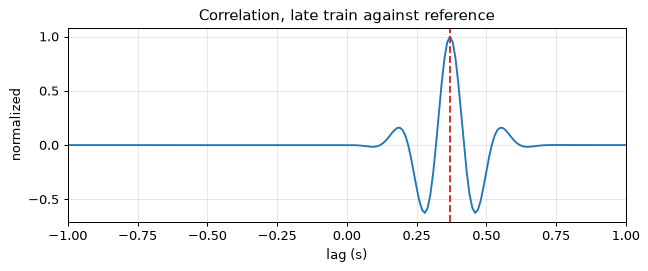

In [36]:
k4 = np.argmax(cc4)
y0, y1, y2 = cc4[k4 - 1], cc4[k4], cc4[k4 + 1]
lag4_sub = lag4 + 0.5 * (y0 - y2) / (y0 - 2 * y1 + y2) / fs      # parabola through the peak and its neighbours
print(f"planted +0.37 s; peak sample {lag4:+.2f} s; parabola {lag4_sub:+.3f} s")
fig, ax = plt.subplots(figsize=(8, 2.8))
ax.plot(lags4, cc4 / cc4.max(), color="C0")
ax.axvline(0.37, color="C3", ls="--")
ax.set(xlim=(-1, 1), xlabel="lag (s)", ylabel="normalized", title="Correlation, late train against reference");

La correlación alcanza su máximo en el desplazamiento plantado. Alrededor del máximo repite el periodo de 5 Hz de los pulsos, con valles a 0.1 s y máximos más pequeños a 0.2 s a cada lado: con ruido, o con formas de onda que difieren entre los dos registros, el valor más grande puede saltar a un máximo vecino, desfasado un periodo. Una referencia con una señal de banda ancha lo hace menos probable. El desplazamiento de 0.37 s es un número entero de muestras (37), así que la parábola, explicada abajo, no cambia nada aquí; el ejercicio 3 prueba un desplazamiento entre muestras.

### El registro de RATT

Las mismas llamadas `signal.correlate` y `signal.correlation_lags` y la misma búsqueda del máximo pasan ahora al registro real, contra su copia intacta. Aquí la copia se desplaza 50 muestras (`np.roll` lleva las últimas 50 muestras al inicio, lejos de la ventana que se usa), y la referencia es el registro intacto, sobre una ventana de 60 s en el tren de ondas P (355 a 415 s).

**Su turno: desplace una copia.** Escriba `z_late`, una copia de `z` con cada muestra movida 0.5 s más tarde (50 muestras), y `zf_late`, su versión filtrada de 1 a 10 Hz con fase cero y `sos`.

*Pista:* `np.roll`; 0.5 s son `0.5 * fs` muestras.

In [37]:
# --- your code
z_late = None     # your code
zf_late = None    # your code
# --- end
your_turn("4.shift", globals())

[4.shift] not answered yet
[z_late, zf_late] using the reference result so the next cells run.


*Solución desarrollada abajo (haga clic en ⋯ para abrirla).*

In [38]:
# Worked solution, open after you tried
# Names end in _sol so that running this cell keeps your own results.
z_late_sol = np.roll(z, int(round(0.5 * fs)))
zf_late_sol = signal.sosfiltfilt(sos, z_late_sol)

In [39]:
P_WINDOW = (355.0, 415.0)                              # s after 06:15:00, the correlation window on the P wave train
w0, w1 = int(P_WINDOW[0] * fs), int(P_WINDOW[1] * fs)
a, b = zf[w0:w1], zf_late[w0:w1]                       # reference window and late window

**Su turno: correlacione.** Escriba `cc`, la correlación cruzada completa de la ventana retrasada `b` con la referencia `a`; `lags`, el retardo de cada valor en segundos; y `lag_peak`, el retardo del valor máximo.

*Pista:* `signal.correlate`, `signal.correlation_lags`, `np.argmax`; ponga primero la ventana retrasada.

In [40]:
# --- your code
cc = None          # your code
lags = None        # seconds, your code
lag_peak = None    # seconds, your code
# --- end
your_turn("4.lag", globals())

[4.lag] not answered yet
[cc, lags, lag_peak] using the reference result so the next cells run.


*Solución desarrollada abajo (haga clic en ⋯ para abrirla).*

In [41]:
# Worked solution, open after you tried
# Names end in _sol so that running this cell keeps your own results.
cc_sol = signal.correlate(b, a, mode="full")
lags_sol = signal.correlation_lags(len(b), len(a), mode="full") / fs
lag_peak_sol = lags_sol[np.argmax(cc_sol)]

La muestra del máximo da el retardo a la muestra más cercana, ±0.005 s. El paso siguiente es opcional. Una parábola que pasa por el máximo y sus dos vecinos ubica el máximo entre muestras. Con y0, y1, y2 los valores en j − 1, j, j + 1, el vértice queda a 0.5 (y0 − y2) / (y0 − 2 y1 + y2) muestras de j.

**Su turno: refine con una parábola (opcional).** Escriba `lag_sub`, el retardo en segundos en el vértice de la parábola que pasa por los tres valores de `cc` alrededor de su máximo.

*Pista:* `np.argmax(cc)` da el índice j del máximo; la fórmula de arriba da el desplazamiento respecto de j en muestras.

In [42]:
# --- your code
lag_sub = None    # seconds, your code
# --- end
your_turn("4.sub", globals())

[4.sub] not answered yet
[lag_sub] using the reference result so the next cells run.


*Solución desarrollada abajo (haga clic en ⋯ para abrirla).*

In [43]:
# Worked solution, open after you tried
# Names end in _sol so that running this cell keeps your own results.
j_sol = np.argmax(cc)
y0_sol, y1_sol, y2_sol = cc[j_sol - 1], cc[j_sol], cc[j_sol + 1]
lag_sub_sol = lag_peak + 0.5 * (y0_sol - y2_sol) / (y0_sol - 2 * y1_sol + y2_sol) / fs

planted +0.50 s; peak sample +0.50 s; parabola +0.500 s


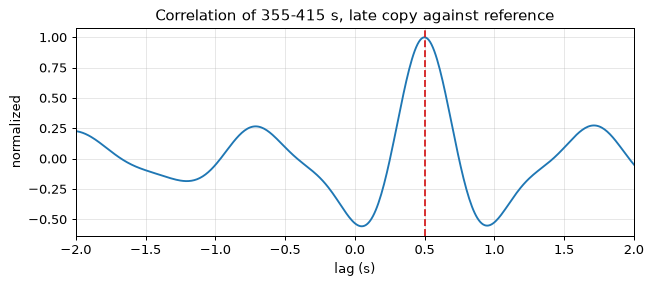

In [44]:
SHIFT_S = 0.5                                          # s, the clock error planted above (50 samples)
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(lags, cc / cc.max(), color="C0")
ax.axvline(lag_peak, color="C3", ls="--")
ax.set(xlim=(-2, 2), xlabel="lag (s)", ylabel="normalized",
       title=f"Correlation of {P_WINDOW[0]:.0f}-{P_WINDOW[1]:.0f} s, late copy against reference")
print(f"planted {SHIFT_S:+.2f} s; peak sample {lag_peak:+.2f} s; parabola {lag_sub:+.3f} s")

La recuperación es exacta por construcción: la copia retrasada es la propia referencia, desplazada, así que las formas de onda coinciden perfectamente. Esto muestra el método, no su exactitud. Con datos reales, la referencia es un sensor colocalizado, una estación vecina (tras restar la diferencia de tiempo de viaje predicha) o la correlación del ruido ambiental entre dos estaciones, seguida día a día. La clase mostró dos casos así:

- **Deriva del reloj en el fondo marino.** Naranjo y otros (2024, *Seismica*, [doi:10.26443/seismica.v3i1.367](https://doi.org/10.26443/seismica.v3i1.367)) correlacionaron el ruido ambiental (0.2 a 0.4 Hz) entre la estación de fondo oceánico O01 y la estación terrestre RET, frente a Islandia. El reloj de O01 ya estaba desfasado 0.31 s al momento del despliegue, así que una recta desde cero hasta la diferencia de reloj medida en la recuperación (−1.02 s) corrige de más; ajustar a la vez un desfase y una deriva alinea las correlaciones.
- **Un error de tiempo de 270 s en US.HDIL, Illinois.** La señal de tiempo GPS se perdió del 3 de octubre de 2022 al 6 de marzo de 2023. La correlación de ruido con la estación N4.N41A, a 133 km, muestra el retardo creciendo hasta +270 s en febrero, y la onda P del sismo de Kahramanmaraş de febrero de 2023 llega +269.9 s tarde a HDIL, frente a +1.2 s en la vecina P43A.

## Parte 5. Los registros de su proyecto (unos 5 min)

**Haga:** escriba tres respuestas breves sobre los datos de su proyecto de equipo.

¿Cuál de los tres problemas (fase del filtro, huecos, error de reloj) aplica a sus datos, y dónde lo vería? ¿Qué reparación aplicaría? ¿Qué anotaría sobre ella para que otra persona pueda rehacerla? Por ejemplo: el tipo de filtro, las frecuencias de esquina y la fase; el inicio, el fin y el valor de relleno de cada hueco, y el intervalo de resguardo; la referencia de tiempo, el retardo o la deriva encontrados y la corrección aplicada.

In [45]:
q5_problem = ""    # which problem, in which part of your data
q5_repair = ""     # the repair you would apply
q5_record = ""     # what you would write down about it
check_text("5.problem", q5_problem); check_text("5.repair", q5_repair); check_text("5.record", q5_record)

[5.problem] not answered yet
[5.repair] not answered yet
[5.record] not answered yet


## Ejercicios (si tiene tiempo)

**1. Un hueco en el tren de ondas P.** La celda siguiente planta el hueco entre 360 y 420 s, en el tren de ondas P (tarea 2 de la clase), y califica ambos métodos con `edge_error`, del calentamiento de la parte 3. Cambie `gap2` para probar otros lugares. ¿Por qué el error con relleno de ceros, relativo a la señal local, es mucho menor que en las ondas superficiales?

In [46]:
# zero-phase filter each run of valid (not NaN) samples on its own; the gap stays NaN
def filter_segments(x, sos):
    out = np.full(len(x), np.nan)
    good = np.flatnonzero(~np.isnan(x))
    for seg in np.split(good, np.flatnonzero(np.diff(good) > 1) + 1):
        out[seg] = signal.sosfiltfilt(sos, x[seg])
    return out


gap2 = (360.0, 420.0)
j0, j1 = int(gap2[0] * fs), int(gap2[1] * fs)
z_gap2 = z.copy(); z_gap2[j0:j1] = 0.0
z_nan2 = z.copy(); z_nan2[j0:j1] = np.nan
for name, test in [("zero-filled", signal.sosfiltfilt(sos, z_gap2)), ("segments", filter_segments(z_nan2, sos))]:
    err, local2 = edge_error(test, zf, t, gap2)
    print(f"gap {gap2[0]:.0f}-{gap2[1]:.0f} s, {name}: {err / local2:.2f} times the local signal ({local2:.0f} counts RMS)")

gap 360-420 s, zero-filled: 2.06 times the local signal (559 counts RMS)


gap 360-420 s, segments: 0.05 times the local signal (559 counts RMS)


**2. Una banda de periodo más largo.** Rehaga la parte 3 en una banda de 0.1 a 1 Hz. Escriba `sos2` y luego ejecute la celda: vuelve a filtrar el registro intacto y ambas reparaciones en la nueva banda y mide el intervalo de resguardo. La ventana de calificación crece a 20 s (`width=20`), porque una ventana de 2 s quedaría dentro del nuevo intervalo de resguardo. ¿Cómo escala el intervalo de resguardo con la frecuencia de esquina inferior?

In [47]:
sos2 = None    # your code: a 2-pole Butterworth band-pass from 0.1 to 1 Hz, as in Part 2
if sos2 is None:
    print("set sos2 first")
else:
    zf2 = signal.sosfiltfilt(sos2, z)
    for name, test in [("zero-filled", signal.sosfiltfilt(sos2, z_gap)), ("segments", filter_segments(z_nan, sos2))]:
        err, local2 = edge_error(test, zf2, t, gap, width=20)
        print(f"0.1-1 Hz, {name}: {err / local2:.2f} times the local signal over 0 to 20 s from the edges")
    before2, after2, bg2 = guard_interval(filter_segments(z_nan, sos2), zf2, t, gap)
    g2 = max(before2, after2)
    print(f"guard {before2:.1f} s before and {after2:.1f} s after the gap: {g2 * 0.1:.1f} periods of the 0.1 Hz corner")

set sos2 first


*Esperado, a partir de la línea resuelta `sos2 = signal.butter(2, [0.1, 1], "bandpass", fs=fs, output="sos")`: relleno con ceros, unas 0.6 veces la señal local, y por segmentos, unas 0.3 veces; un intervalo de resguardo de unos 11 s antes y 10 s después del hueco, aproximadamente un periodo de la frecuencia de esquina inferior.*

**3. Un error de reloj entre muestras.** Un desplazamiento de exactamente 50 muestras le deja poco que hacer a la parábola. La celda siguiente planta un desplazamiento de 0.537 s multiplicando el espectro por una rampa de fase, de modo que el desplazamiento cae entre muestras. Repita sus líneas de la parte 4 sobre la ventana `b3` contra `a`: ¿qué dan la muestra del máximo y la parábola?

In [48]:
f = np.fft.rfftfreq(len(z), 1 / fs)
z_frac = np.fft.irfft(np.fft.rfft(z) * np.exp(-2j * np.pi * f * 0.537), n=len(z))   # 0.537 s later
b3 = signal.sosfiltfilt(sos, z_frac)[w0:w1]
# your code: cross-correlate b3 with a, take the peak sample, then the parabola

In [49]:
# Worked solution, open after you tried
cc3 = signal.correlate(b3, a, mode="full")
lags3 = signal.correlation_lags(len(b3), len(a), mode="full") / fs
k = np.argmax(cc3)
sub3 = lags3[k] + 0.5 * (cc3[k - 1] - cc3[k + 1]) / (cc3[k - 1] - 2 * cc3[k] + cc3[k + 1]) / fs
print(f"planted +0.537 s; peak sample {lags3[k]:+.3f} s; parabola {sub3:+.4f} s")

planted +0.537 s; peak sample +0.540 s; parabola +0.5367 s


**Datos y créditos.** Formas de onda y metadatos de estación: red UW, University of Washington (1963), Pacific Northwest Seismic Network, [doi:10.7914/SN/UW](https://doi.org/10.7914/SN/UW). Los datos se obtuvieron del archivo de datos NSF NGF operado por EarthScope Consortium (subvención NSF 2435260). Parámetros del sismo: evento [ak0219neiszm](https://earthquake.usgs.gov/earthquakes/eventpage/ak0219neiszm) del ComCat del USGS, de dominio público. Líneas de costa y fronteras: Natural Earth, de dominio público; `snapshots/naturalearth_npacific_coast.csv` se construye con `snapshots/make_naturalearth_npacific_coast.py`. Copias del curso de los datos sísmicos, sus URL de origen y sus huellas: `snapshots/ratt_chignik_2021-07-29.provenance.json`, construido con `snapshots/make_ratt_chignik_2021-07-29.py`.